# Car Data Classification and Ensemble Learning

**Assignment:** Assignment 6.1  
**Activities:** Activity 4.01 and Activity 4.02

## Objective

The purpose of this assignment is to classify cars based on their features using a Decision Tree, Random Forest, and Extra Trees classifier. The models will be evaluated and compared to determine which approach provides the most reliable predictions.

In [3]:
# Import libraries for data analysis and machine learning.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Loading the Car Evaluation Dataset

The Car Evaluation dataset contains information about vehicles, including buying price, maintenance cost, number of doors, passenger capacity, luggage space, and safety. The target variable represents the overall evaluation of each car.

The dataset will be used to train machine learning models that classify vehicles into different evaluation categories.

In [4]:
# Load the Car Evaluation dataset correctly.
# The first row of the CSV already contains column headers.

import pandas as pd

url = "https://raw.githubusercontent.com/PacktWorkshops/The-Applied-Artificial-Intelligence-Workshop/master/Datasets/car.csv"

df = pd.read_csv(url, header=0)

# Standardize column names and remove accidental whitespace.
df.columns = df.columns.str.strip().str.lower()

for column in df.columns:
    df[column] = df[column].astype(str).str.strip()

# Verify the dataset.
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\nTarget class counts:")
print(df["class"].value_counts())

print("\nNumber of unique target classes:", df["class"].nunique())

Dataset shape: (1728, 7)

Column names: ['buying', 'maintenance', 'doors', 'persons', 'luggage_boot', 'safety', 'class']

First five rows:


,buying,maintenance,doors,persons,luggage_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc



Target class counts:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

Number of unique target classes: 4


In [5]:
print(df.shape)
print(df.head(10).to_string())
print(df["class"].value_counts(dropna=False).to_dict())

(1728, 7)
  buying maintenance doors persons luggage_boot safety  class
0  vhigh       vhigh     2       2        small    low  unacc
1  vhigh       vhigh     2       2        small    med  unacc
2  vhigh       vhigh     2       2        small   high  unacc
3  vhigh       vhigh     2       2          med    low  unacc
4  vhigh       vhigh     2       2          med    med  unacc
5  vhigh       vhigh     2       2          med   high  unacc
6  vhigh       vhigh     2       2          big    low  unacc
7  vhigh       vhigh     2       2          big    med  unacc
8  vhigh       vhigh     2       2          big   high  unacc
9  vhigh       vhigh     2       4        small    low  unacc
{'unacc': 1210, 'acc': 384, 'good': 69, 'vgood': 65}


In [6]:
# Display the first five rows to understand the structure of the data.

df.head()

,buying,maintenance,doors,persons,luggage_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [7]:
# Check data types, missing values, and duplicate records.

print("Dataset information:")
df.info()

print("\nMissing values by column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   buying        1728 non-null   object
 1   maintenance   1728 non-null   object
 2   doors         1728 non-null   object
 3   persons       1728 non-null   object
 4   luggage_boot  1728 non-null   object
 5   safety        1728 non-null   object
 6   class         1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB

Missing values by column:
buying          0
maintenance     0
doors           0
persons         0
luggage_boot    0
safety          0
class           0
dtype: int64

Number of duplicate rows: 0


In [8]:
# Display the number of examples in each car evaluation category.

print("Class distribution:")
print(df["class"].value_counts())

print("\nClass distribution as percentages:")
print((df["class"].value_counts(normalize=True) * 100).round(2))

Class distribution:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

Class distribution as percentages:
class
unacc    70.02
acc      22.22
good      3.99
vgood     3.76
Name: proportion, dtype: float64


## 2. Data Preprocessing

All six input features are categorical. Machine learning classifiers require these values to be represented numerically. An OrdinalEncoder will transform the categorical features into numeric codes.

The target column, `class`, will be separated from the input features. The data will then be divided into training and testing sets. A stratified split will help preserve the class proportions in both sets.

The encoder will be fitted on the training data only to avoid using information from the test set during preprocessing.

In [9]:
# Check the target labels and their frequencies.

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget class counts:")
print(df["class"].value_counts(dropna=False))

print("\nUnique target labels:")
print(df["class"].unique())

Dataset shape: (1728, 7)

Column names:
['buying', 'maintenance', 'doors', 'persons', 'luggage_boot', 'safety', 'class']

Target class counts:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

Unique target labels:
['unacc' 'acc' 'vgood' 'good']


In [10]:
# Separate input features and target labels.

X = df.drop(columns=["class"])
y = df["class"]

# Check whether stratified splitting is possible.
class_counts = y.value_counts()

print("Target class counts:")
print(class_counts)

if class_counts.min() < 2:
    raise ValueError(
        "At least one class has fewer than 2 rows. "
        "Check the dataset loading and target labels in Cell 4."
    )

# Split the dataset into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of input features:", X_train.shape[1])
print("\nTraining target distribution:")
print(y_train.value_counts())

Target class counts:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

Training samples: 1382
Testing samples: 346
Number of input features: 6

Training target distribution:
class
unacc    968
acc      307
good      55
vgood     52
Name: count, dtype: int64


## 3. Activity 4.01: Decision Tree Classification

A Decision Tree learns a set of rules from the training data to predict the evaluation category of a car. It splits observations according to feature values and uses the resulting branches to make predictions.

The model will be trained on the training set and evaluated on the unseen test set. Accuracy, precision, recall, F1-score, and a confusion matrix will be used to assess its performance.

In [11]:
# Create a preprocessing and classification pipeline.
# The encoder is fitted only on the training data.

tree_pipeline = Pipeline([
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        criterion="gini"
    ))
])

# Train the model.
tree_pipeline.fit(X_train, y_train)

# Predict car categories for the test set.
tree_predictions = tree_pipeline.predict(X_test)

print("Decision Tree model trained successfully.")
print("Test accuracy:", round(
    accuracy_score(y_test, tree_predictions), 4
))

Decision Tree model trained successfully.
Test accuracy: 0.9855


Decision Tree Classification Report:

              precision    recall  f1-score   support

         acc       0.95      0.99      0.97        77
        good       0.93      1.00      0.97        14
       unacc       1.00      0.99      1.00       242
       vgood       1.00      0.85      0.92        13

    accuracy                           0.99       346
   macro avg       0.97      0.96      0.96       346
weighted avg       0.99      0.99      0.99       346



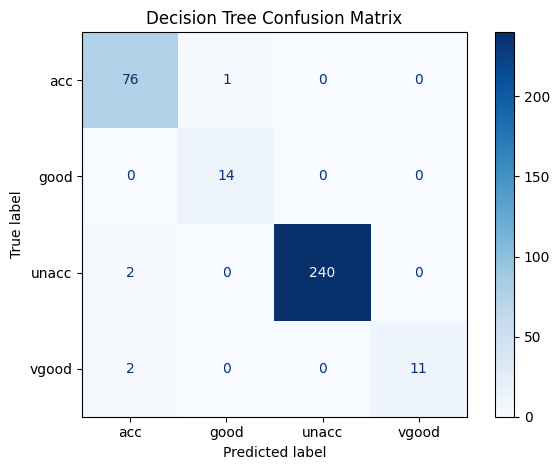

In [12]:
# Evaluate the Decision Tree using several classification metrics.

print("Decision Tree Classification Report:\n")
print(classification_report(
    y_test,
    tree_predictions,
    zero_division=0
))

# Display the confusion matrix.
tree_labels = sorted(y.unique())
tree_cm = confusion_matrix(
    y_test,
    tree_predictions,
    labels=tree_labels
)

ConfusionMatrixDisplay(
    confusion_matrix=tree_cm,
    display_labels=tree_labels
).plot(cmap="Blues", values_format="d")

plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

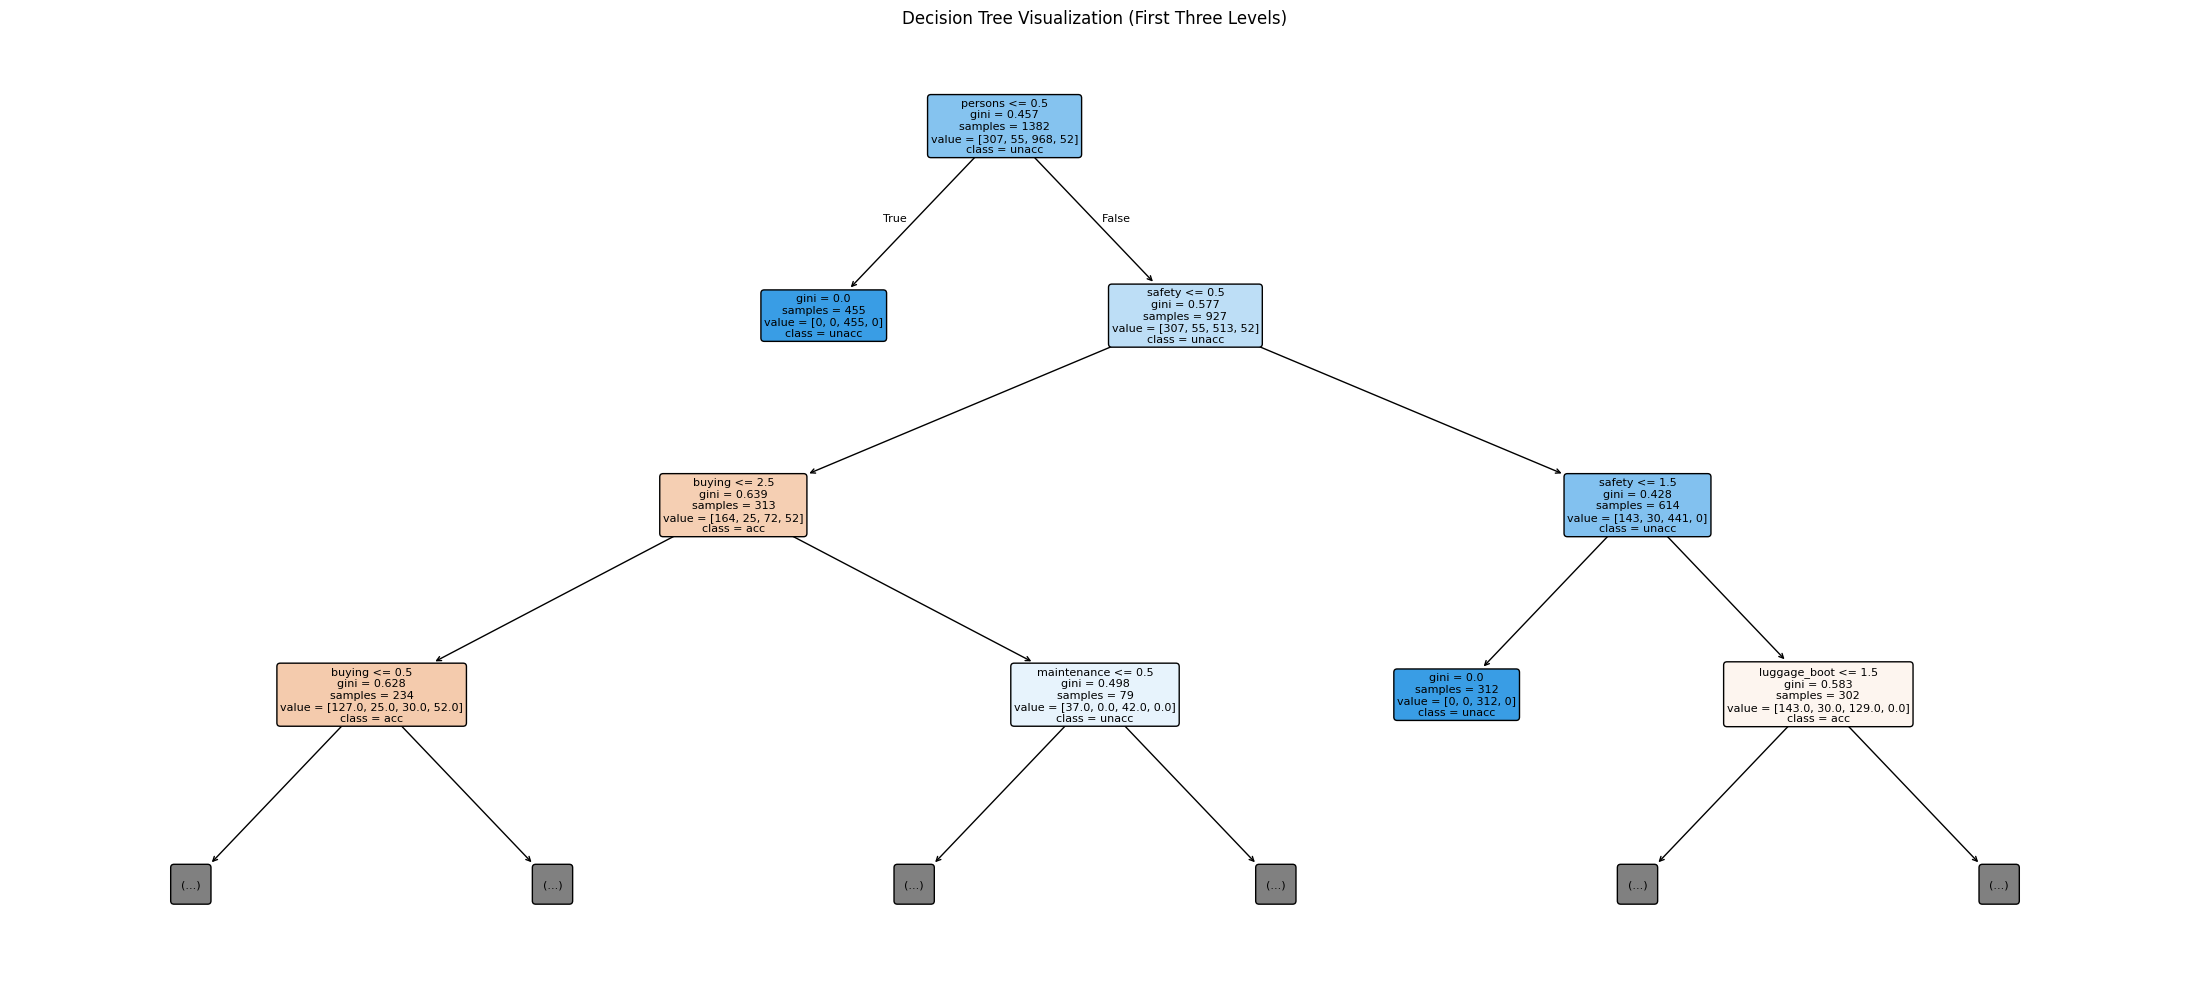

In [13]:
# Visualize the trained Decision Tree to inspect its decision rules.

plt.figure(figsize=(22, 10))

plot_tree(
    tree_pipeline.named_steps["classifier"],
    feature_names=X.columns,
    class_names=tree_labels,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualization (First Three Levels)")
plt.tight_layout()
plt.show()

This visualization shows the upper levels of the tree. The plot is limited to three levels to keep the notebook PDF readable; the model itself is not limited to three levels.

## 4. Activity 4.02: Random Forest Classification

Random Forest combines predictions from multiple decision trees. Each tree is trained using randomized samples and feature selection, helping the ensemble reduce the instability of a single tree.

Extra Trees, or Extremely Randomized Trees, is another ensemble method that adds randomness when selecting split thresholds.

Both models will be trained and evaluated using the same training and test sets used for the Decision Tree. This provides a fairer comparison of their performance.

In [14]:
# Build the Random Forest pipeline.

rf_pipeline = Pipeline([
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Build the Extra Trees pipeline.

et_pipeline = Pipeline([
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )),
    ("classifier", ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Train both ensemble models.
rf_pipeline.fit(X_train, y_train)
et_pipeline.fit(X_train, y_train)

# Generate test-set predictions.
rf_predictions = rf_pipeline.predict(X_test)
et_predictions = et_pipeline.predict(X_test)

print("Random Forest and Extra Trees models trained successfully.")
print("Random Forest accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))
print("Extra Trees accuracy:",
      round(accuracy_score(y_test, et_predictions), 4))

Random Forest and Extra Trees models trained successfully.
Random Forest accuracy: 0.9798
Extra Trees accuracy: 0.9798


In [15]:
# Print detailed evaluation metrics for both ensemble models.

print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test, rf_predictions, zero_division=0
))

print("\nEXTRA TREES CLASSIFICATION REPORT")
print(classification_report(
    y_test, et_predictions, zero_division=0
))

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

         acc       0.97      0.94      0.95        77
        good       0.93      0.93      0.93        14
       unacc       0.98      1.00      0.99       242
       vgood       1.00      0.92      0.96        13

    accuracy                           0.98       346
   macro avg       0.97      0.95      0.96       346
weighted avg       0.98      0.98      0.98       346


EXTRA TREES CLASSIFICATION REPORT
              precision    recall  f1-score   support

         acc       0.95      0.96      0.95        77
        good       1.00      0.93      0.96        14
       unacc       0.99      1.00      0.99       242
       vgood       1.00      0.85      0.92        13

    accuracy                           0.98       346
   macro avg       0.98      0.93      0.96       346
weighted avg       0.98      0.98      0.98       346



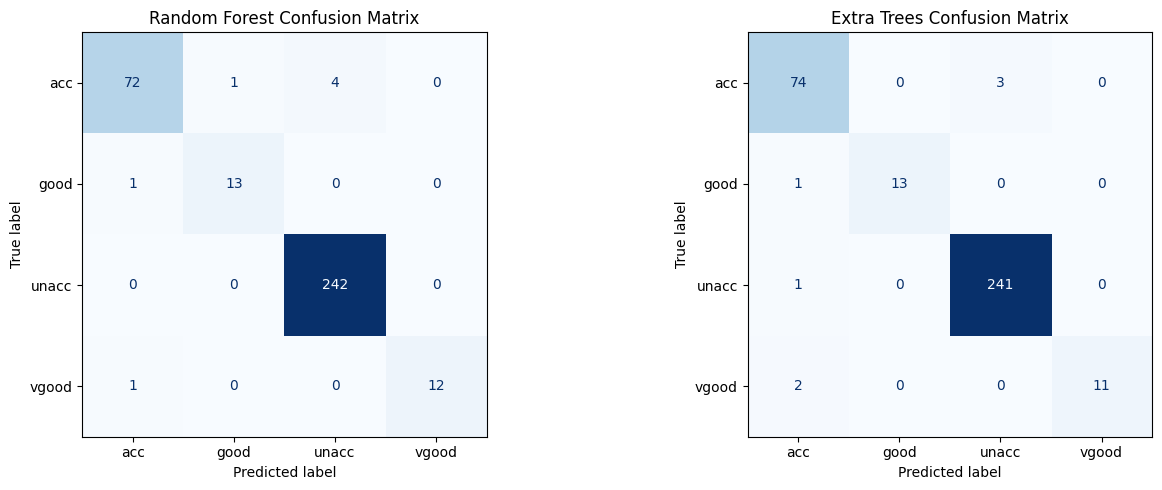

In [16]:
# Compare the types of correct and incorrect predictions.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, predictions, model_name in [
    (axes[0], rf_predictions, "Random Forest"),
    (axes[1], et_predictions, "Extra Trees")
]:
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=tree_labels
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=tree_labels
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} Confusion Matrix")

plt.tight_layout()
plt.show()

The diagonal of a confusion matrix represents correct predictions. The values outside the diagonal show which categories were incorrectly predicted.

## 5. Hyperparameter Optimization

The initial ensemble models use 200 trees. Their performance may depend on settings such as the number of trees and the maximum tree depth.

GridSearchCV will test a small set of parameter combinations using stratified cross-validation. Macro F1-score will be used for model selection so that the performance of each class contributes equally to the tuning objective.

The held-out test set will remain separate from the tuning process and will be used for the final evaluation.

In [17]:
# Tune the Random Forest using cross-validation.

rf_parameters = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_parameters,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    refit=True
)

rf_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)
print("Best cross-validation macro F1-score:",
      round(rf_search.best_score_, 4))

Best Random Forest parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}
Best cross-validation macro F1-score: 0.9193


In [18]:
# Tune the Extra Trees classifier using the same validation approach.

et_parameters = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2]
}

et_search = GridSearchCV(
    estimator=et_pipeline,
    param_grid=et_parameters,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    refit=True
)

et_search.fit(X_train, y_train)

print("Best Extra Trees parameters:")
print(et_search.best_params_)
print("Best cross-validation macro F1-score:",
      round(et_search.best_score_, 4))

Best Extra Trees parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}
Best cross-validation macro F1-score: 0.885


In [19]:
# Evaluate the baseline Decision Tree and the optimized ensemble models.

models = {
    "Decision Tree": tree_pipeline,
    "Random Forest (Initial)": rf_pipeline,
    "Extra Trees (Initial)": et_pipeline,
    "Random Forest (Tuned)": rf_search.best_estimator_,
    "Extra Trees (Tuned)": et_search.best_estimator_
}

comparison_rows = []

for name, model in models.items():
    predictions = model.predict(X_test)

    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": __import__(
            "sklearn.metrics", fromlist=["f1_score"]
        ).f1_score(
            y_test, predictions, average="macro"
        )
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

print("Model Comparison on the Test Set")
display(comparison_df.round(4))

best_model_name = comparison_df.iloc[0]["Model"]
print("\nBest model by test macro F1-score:", best_model_name)

Model Comparison on the Test Set


,Model,Accuracy,Macro F1
0,Decision Tree,0.9855,0.9615
1,Random Forest (Initial),0.9798,0.9585
2,Random Forest (Tuned),0.9798,0.9585
3,Extra Trees (Initial),0.9798,0.9566
4,Extra Trees (Tuned),0.9798,0.9566



Best model by test macro F1-score: Decision Tree


,Feature,Importance
5,safety,0.2734
3,persons,0.2265
0,buying,0.1872
1,maintenance,0.1566
4,luggage_boot,0.0856
2,doors,0.0707


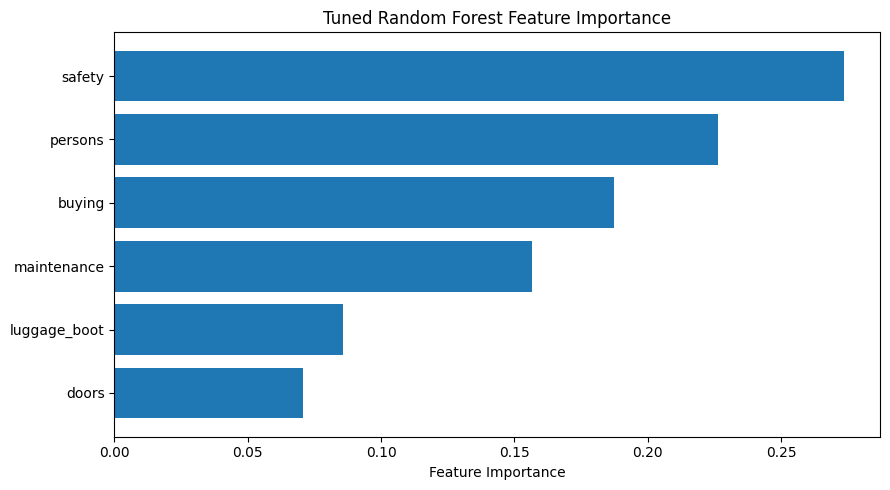

In [20]:
# Examine which input features contribute most to the tuned Random Forest.

best_rf = rf_search.best_estimator_
rf_classifier = best_rf.named_steps["classifier"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_classifier.feature_importances_
}).sort_values(
    by="Importance", ascending=False
)

display(feature_importance.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Tuned Random Forest Feature Importance")
plt.tight_layout()
plt.show()

This cell helps explain which car attributes were most useful to the tuned Random Forest. Feature importance indicates predictive contribution, not causation.

## 6. Conclusion

This assignment applied three types of tree-based classification models to the Car Evaluation dataset: Decision Tree, Random Forest, and Extra Trees. The models were evaluated using a held-out test set to determine how accurately they could classify cars into different evaluation categories.

The Decision Tree model achieved the best overall performance, with an accuracy of **98.55%** and a macro F1-score of **0.9615**. The initial Random Forest model achieved an accuracy of 97.98% and a macro F1-score of 0.9585. The initial Extra Trees model also achieved 97.98% accuracy, with a macro F1-score of 0.9566.

The hyperparameter tuning process did not improve the test-set results for either ensemble model. The tuned Random Forest maintained an accuracy of 97.98% and a macro F1-score of 0.9585, while the tuned Extra Trees model maintained an accuracy of 97.98% and a macro F1-score of 0.9566. This indicates that the selected parameter combinations did not provide a measurable improvement over the initial models on this test set.

Overall, the Decision Tree was the strongest model among the five configurations evaluated. Although Random Forest and Extra Trees combine multiple trees, they did not outperform the single Decision Tree on this dataset. These results demonstrate the importance of evaluating machine learning models using multiple metrics rather than accuracy alone. Macro F1-score is particularly useful because it gives equal weight to the performance of each class.

For a car rental company, this model could help classify vehicles based on characteristics such as buying price, maintenance cost, passenger capacity, luggage space, and safety. However, the model's predictions should support business decisions rather than replace consideration of customer preferences, operating costs, and vehicle safety.
